In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../03_Cleaned_Data/kerala_tourism_master_dataset_25_destinations.csv"
)

print("Dataset shape:", df.shape)

Dataset shape: (25, 68)


In [2]:
missing = df.isnull().sum()

print(missing[missing > 0])


Visitor_Estimation_Note_2022               12
Visitor_Estimation_Note_2023               11
Visitor_Estimation_Note_2024               11
Nearest_Railway_Distance_km_numeric         5
Alternative_Railway_Distance_km_numeric    14
dtype: int64


In [3]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate destinations:",
    df["Destination"].duplicated().sum()
)

Duplicate rows: 0
Duplicate destinations: 0


In [4]:
numeric_cols = df.select_dtypes(
    include=["int64", "float64"]
)

print(numeric_cols.columns.tolist())


['No', 'Latitude', 'Longitude', 'Attraction_Count', 'Hotels', 'Resorts', 'Homestays_Vacation_Rentals', 'Restaurants', 'Bakeries_Confectioneries', 'Cafes_Tea_Rooms', 'Hotels_Average_Rating', 'Resorts_Average_Rating', 'Homestays_Average_Rating', 'Restaurants_Average_Rating', 'Source_Reported_Count', 'Domestic_Visitors_2022', 'Foreign_Visitors_2022', 'Total_Visitors_2022', 'Domestic_Visitors_2023', 'Foreign_Visitors_2023', 'Total_Visitors_2023', 'Domestic_Visitors_2024', 'Foreign_Visitors_2024', 'Total_Visitors_2024', 'Nearest_Railway_Distance_km_numeric', 'Alternative_Railway_Distance_km_numeric', 'Nearest_Airport_Distance_km_numeric']


In [5]:
features = [
    "Attraction_Count",
    "Hotels",
    "Resorts",
    "Homestays_Vacation_Rentals",
    "Restaurants",
    "Hotels_Average_Rating",
    "Resorts_Average_Rating",
    "Nearest_Airport_Distance_km_numeric"
]

print(df[features].isnull().sum())

Attraction_Count                       0
Hotels                                 0
Resorts                                0
Homestays_Vacation_Rentals             0
Restaurants                            0
Hotels_Average_Rating                  0
Resorts_Average_Rating                 0
Nearest_Airport_Distance_km_numeric    0
dtype: int64


In [6]:
df.to_csv(
    "../03_Cleaned_Data/master_working_copy.csv",
    index=False
)

print("Working copy saved successfully!")

Working copy saved successfully!


In [7]:
print(df[features].isnull().sum())

Attraction_Count                       0
Hotels                                 0
Resorts                                0
Homestays_Vacation_Rentals             0
Restaurants                            0
Hotels_Average_Rating                  0
Resorts_Average_Rating                 0
Nearest_Airport_Distance_km_numeric    0
dtype: int64


In [8]:
features = [
    "Attraction_Count",
    "Hotels",
    "Resorts",
    "Homestays_Vacation_Rentals",
    "Restaurants",
    "Hotels_Average_Rating",
    "Resorts_Average_Rating",
    "Nearest_Airport_Distance_km_numeric"
]

print(df[features].isnull().sum())

Attraction_Count                       0
Hotels                                 0
Resorts                                0
Homestays_Vacation_Rentals             0
Restaurants                            0
Hotels_Average_Rating                  0
Resorts_Average_Rating                 0
Nearest_Airport_Distance_km_numeric    0
dtype: int64


In [9]:
ml_df = df[["Destination"] + features].copy()

print(ml_df.head())

  Destination  Attraction_Count  Hotels  Resorts  Homestays_Vacation_Rentals  \
0      Munnar                 9     245      161                         450   
1     Wayanad                17     184      267                         580   
2     Vagamon                 5      86      142                         310   
3    Thekkady                 4     112      154                         290   
4   Alappuzha                 4     142      118                         460   

   Restaurants  Hotels_Average_Rating  Resorts_Average_Rating  \
0          214                    4.2                     4.4   
1          412                    4.1                     4.5   
2           94                    4.0                     4.4   
3          126                    4.2                     4.5   
4          274                    4.1                     4.4   

   Nearest_Airport_Distance_km_numeric  
0                                107.0  
1                                100.0  
2    

In [10]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X = ml_df[features].copy()

# Treat unreported business counts as missing.
business_cols = [
    "Hotels",
    "Resorts",
    "Homestays_Vacation_Rentals",
    "Restaurants"
]

X[business_cols] = X[business_cols].replace(0, np.nan)

X_clean = pd.DataFrame(
    imputer.fit_transform(X),
    columns=features,
    index=ml_df.index
)

print(X_clean.isnull().sum())

Attraction_Count                       0
Hotels                                 0
Resorts                                0
Homestays_Vacation_Rentals             0
Restaurants                            0
Hotels_Average_Rating                  0
Resorts_Average_Rating                 0
Nearest_Airport_Distance_km_numeric    0
dtype: int64


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_clean)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=ml_df.index
)

print(X_scaled.head())

   Attraction_Count    Hotels   Resorts  Homestays_Vacation_Rentals  \
0          1.610100  1.218586  1.236753                    1.087180   
1          4.165815  0.670079  2.707097                    1.749101   
2          0.332243 -0.211131  0.973201                    0.374342   
3          0.012779  0.022660  1.139655                    0.272508   
4          0.012779  0.292418  0.640293                    1.138097   

   Restaurants  Hotels_Average_Rating  Resorts_Average_Rating  \
0     0.044412               1.230829                0.424264   
1     0.729273               0.441836                1.131371   
2    -0.370655              -0.347157                0.424264   
3    -0.259970               1.230829                1.131371   
4     0.251946               0.441836                0.424264   

   Nearest_Airport_Distance_km_numeric  
0                             1.028905  
1                             0.834458  
2                             1.112240  
3                 

In [12]:
final_ml_df = pd.concat(
    [ml_df[["Destination"]], X_scaled],
    axis=1
)

final_ml_df.to_csv(
    "../03_Cleaned_Data/final_ml_dataset.csv",
    index=False
)

print("ML dataset saved successfully!")
print("Dataset shape:", final_ml_df.shape)

ML dataset saved successfully!
Dataset shape: (25, 9)


In [13]:
final_ml_df = pd.concat(
    [ml_df[["Destination"]], X_scaled],
    axis=1
)


In [15]:
final_ml_df.to_csv(
    "../03_Cleaned_Data/final_ml_dataset.csv",
    index=False
)

In [16]:
print("ML dataset saved successfully!")
print("Dataset shape:", final_ml_df.shape)

ML dataset saved successfully!
Dataset shape: (25, 9)


In [17]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../03_Cleaned_Data/kerala_tourism_master_dataset_25_destinations.csv"
)

print("Master dataset loaded successfully!")

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

Master dataset loaded successfully!
Dataset shape: (25, 68)

Column names:
['No', 'Destination', 'District', 'Latitude', 'Longitude', 'Attraction_Count', 'Hotels', 'Resorts', 'Homestays_Vacation_Rentals', 'Restaurants', 'Bakeries_Confectioneries', 'Cafes_Tea_Rooms', 'Hotels_Average_Rating', 'Resorts_Average_Rating', 'Homestays_Average_Rating', 'Restaurants_Average_Rating', 'Approximation_And_Category_Notes', 'Source', 'Missing_Category_Convention', 'Count_Convention', 'Collection_Date', 'Rating_Scale', 'Review_Counts', 'Business_Counts', 'Source_Reported_Count', 'Count_Matches_Entries', 'Notes', 'Domestic_Visitors_2022', 'Foreign_Visitors_2022', 'Total_Visitors_2022', 'Domestic_Status_2022', 'Foreign_Status_2022', 'Total_Status_2022', 'Visitor_Estimation_Note_2022', 'Visitor_Data_Type_2022', 'Visitor_Source_2022', 'Domestic_Visitors_2023', 'Foreign_Visitors_2023', 'Total_Visitors_2023', 'Domestic_Status_2023', 'Foreign_Status_2023', 'Total_Status_2023', 'Visitor_Estimation_Note_2023', 

In [18]:
features = [
    "Attraction_Count",
    "Hotels",
    "Resorts",
    "Homestays_Vacation_Rentals",
    "Restaurants",
    "Hotels_Average_Rating",
    "Resorts_Average_Rating",
    "Nearest_Airport_Distance_km_numeric"
]

print("Missing values:")
print(df[features].isnull().sum())

print("\nZero values:")
print((df[features] == 0).sum())

print("\nFeature summary:")
print(df[features].describe().round(2))

Missing values:
Attraction_Count                       0
Hotels                                 0
Resorts                                0
Homestays_Vacation_Rentals             0
Restaurants                            0
Hotels_Average_Rating                  0
Resorts_Average_Rating                 0
Nearest_Airport_Distance_km_numeric    0
dtype: int64

Zero values:
Attraction_Count                       0
Hotels                                 1
Resorts                                3
Homestays_Vacation_Rentals             3
Restaurants                            0
Hotels_Average_Rating                  0
Resorts_Average_Rating                 0
Nearest_Airport_Distance_km_numeric    0
dtype: int64

Feature summary:
       Attraction_Count  Hotels  Resorts  Homestays_Vacation_Rentals  \
count             25.00   25.00    25.00                       25.00   
mean               3.96  106.92    66.80                      212.48   
std                3.19  115.28    76.95              

In [19]:
zero_columns = [
    "Hotels",
    "Resorts",
    "Homestays_Vacation_Rentals"
]

for column in zero_columns:

    print("\nColumn:", column)

    print(
        df.loc[
            df[column] == 0,
            ["Destination", "District", column,
             "Approximation_And_Category_Notes"]
        ].to_string(index=False)
    )


Column: Hotels
Destination  District  Hotels                                                                                              Approximation_And_Category_Notes
  Ranipuram Kasaragod       0 Homestays combine 12 Valley View Serviced Villas + 20+ Village Farmstays (minimum 32); Restaurants 15+ recorded as minimum 15

Column: Resorts
Destination           District  Resorts                                                                                                                                                                                       Approximation_And_Category_Notes
  Guruvayur           Thrissur        0                                                                                           Homestays 160+; Bakeries count is combined Traditional Bakeries & Tiffin Cafés (72); Hotels includes 12 Devaswom Rest Houses
    Ponmudi Thiruvananthapuram        0                                                                                                          

In [20]:
df_ml = df.copy()

zero_columns = [
    "Hotels",
    "Resorts",
    "Homestays_Vacation_Rentals"
]

for column in zero_columns:
    df_ml.loc[df_ml[column] == 0, column] = np.nan

print("Unknown values after replacing zero counts:")

print(df_ml[features].isnull().sum())

Unknown values after replacing zero counts:
Attraction_Count                       0
Hotels                                 1
Resorts                                3
Homestays_Vacation_Rentals             3
Restaurants                            0
Hotels_Average_Rating                  0
Resorts_Average_Rating                 0
Nearest_Airport_Distance_km_numeric    0
dtype: int64


In [21]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

df_ml[features] = imputer.fit_transform(df_ml[features])

print("Median imputation completed!")

print("\nMissing values after imputation:")
print(df_ml[features].isnull().sum())

print("\nUpdated feature summary:")
print(df_ml[features].describe().round(2))

Median imputation completed!

Missing values after imputation:
Attraction_Count                       0
Hotels                                 0
Resorts                                0
Homestays_Vacation_Rentals             0
Restaurants                            0
Hotels_Average_Rating                  0
Resorts_Average_Rating                 0
Nearest_Airport_Distance_km_numeric    0
dtype: int64

Updated feature summary:
       Attraction_Count  Hotels  Resorts  Homestays_Vacation_Rentals  \
count             25.00   25.00    25.00                       25.00   
mean               3.96  109.48    71.84                      236.48   
std                3.19  113.50    73.58                      200.45   
min                1.00   14.00     8.00                       15.00   
25%                2.00   28.00    14.00                       45.00   
50%                3.00   64.00    42.00                      200.00   
75%                4.00  142.00   118.00                      390.

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df_ml[features])

df_scaled = pd.DataFrame(
    scaled_data,
    columns=features
)

print("Feature scaling completed!")

print("\nScaled dataset:")
print(df_scaled.head())

print("\nScaled feature means:")
print(df_scaled.mean().round(2))

print("\nScaled feature standard deviations:")
print(df_scaled.std().round(2))

Feature scaling completed!

Scaled dataset:
   Attraction_Count    Hotels   Resorts  Homestays_Vacation_Rentals  \
0          1.610100  1.218586  1.236753                    1.087180   
1          4.165815  0.670079  2.707097                    1.749101   
2          0.332243 -0.211131  0.973201                    0.374342   
3          0.012779  0.022660  1.139655                    0.272508   
4          0.012779  0.292418  0.640293                    1.138097   

   Restaurants  Hotels_Average_Rating  Resorts_Average_Rating  \
0     0.044412               1.230829                0.424264   
1     0.729273               0.441836                1.131371   
2    -0.370655              -0.347157                0.424264   
3    -0.259970               1.230829                1.131371   
4     0.251946               0.441836                0.424264   

   Nearest_Airport_Distance_km_numeric  
0                             1.028905  
1                             0.834458  
2              

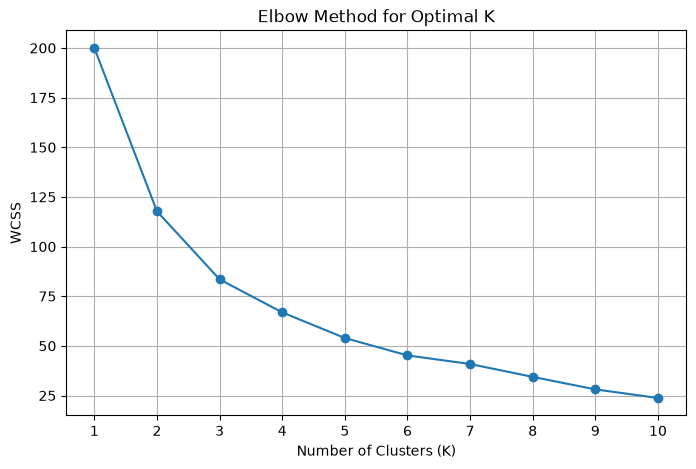

In [23]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(df_scaled)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(df_scaled)

    score = silhouette_score(df_scaled, labels)

    silhouette_scores.append(score)

    print("K =", k, "| Silhouette Score =", round(score, 4))

K = 2 | Silhouette Score = 0.3559
K = 3 | Silhouette Score = 0.3899
K = 4 | Silhouette Score = 0.3501
K = 5 | Silhouette Score = 0.2501
K = 6 | Silhouette Score = 0.2424
K = 7 | Silhouette Score = 0.2303
K = 8 | Silhouette Score = 0.179


In [25]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df_ml["Cluster"] = kmeans.fit_predict(df_scaled)

print("K-Means clustering completed!")

print("\nCluster distribution:")
print(df_ml["Cluster"].value_counts().sort_index())

print("\nDestination cluster assignments:")

print(
    df_ml[["Destination", "Cluster"]]
    .sort_values("Cluster")
    .to_string(index=False)
)

K-Means clustering completed!

Cluster distribution:
Cluster
0     3
1    14
2     8
Name: count, dtype: int64

Destination cluster assignments:
            Destination  Cluster
         Kozhikode City        0
Thiruvananthapuram City        0
             Kochi City        0
       Parassinikkadavu        1
              Guruvayur        1
             Malampuzha        1
                  Bekal        1
           Athirappilly        1
               Palaruvi        1
              Ranipuram        1
             Thalassery        1
          Silent Valley        1
          Nelliyampathy        1
                  Konni        1
               Thenmala        1
                Ponmudi        1
  Meenkunnu–Payyambalam        1
                Wayanad        2
                Vagamon        2
               Thekkady        2
              Alappuzha        2
              Kumarakom        2
                Varkala        2
                Kovalam        2
                 Munnar       

In [26]:
cluster_profile = (
    df_ml.groupby("Cluster")[features]
    .mean()
    .round(2)
)

print("Cluster Feature Profiles:")
print(cluster_profile)

print("\nNumber of destinations in each cluster:")
print(df_ml["Cluster"].value_counts().sort_index())

Cluster Feature Profiles:
         Attraction_Count  Hotels  Resorts  Homestays_Vacation_Rentals  \
Cluster                                                                  
0                    4.67  346.00    53.67                      490.00   
1                    2.36   39.21    22.93                       88.00   
2                    6.50  143.75   164.25                      401.25   

         Restaurants  Hotels_Average_Rating  Resorts_Average_Rating  \
Cluster                                                               
0             912.67                   4.17                    4.40   
1              53.79                   3.96                    4.27   
2             192.25                   4.14                    4.44   

         Nearest_Airport_Distance_km_numeric  
Cluster                                       
0                                      22.33  
1                                      70.71  
2                                      86.50  

Number of d

In [27]:
cluster_names = {
    0: "Urban Tourism and Commercial Hubs",
    1: "Developing and Nature-Based Destinations",
    2: "Established Leisure and Resort Destinations"
}

df_ml["Cluster_Name"] = df_ml["Cluster"].map(cluster_names)

cluster_results = df_ml[
    ["Destination", "District", "Cluster", "Cluster_Name"]
]

print(cluster_results.to_string(index=False))

cluster_results.to_csv(
    "../07_Machine_Learning/kerala_tourism_cluster_assignments.csv",
    index=False
)

print("\nCluster assignments saved successfully!")

            Destination           District  Cluster                                Cluster_Name
                 Munnar             Idukki        2 Established Leisure and Resort Destinations
                Wayanad            Wayanad        2 Established Leisure and Resort Destinations
                Vagamon             Idukki        2 Established Leisure and Resort Destinations
               Thekkady             Idukki        2 Established Leisure and Resort Destinations
              Alappuzha          Alappuzha        2 Established Leisure and Resort Destinations
              Kumarakom           Kottayam        2 Established Leisure and Resort Destinations
                Varkala Thiruvananthapuram        2 Established Leisure and Resort Destinations
                Kovalam Thiruvananthapuram        2 Established Leisure and Resort Destinations
             Kochi City          Ernakulam        0           Urban Tourism and Commercial Hubs
         Kozhikode City          Kozhiko

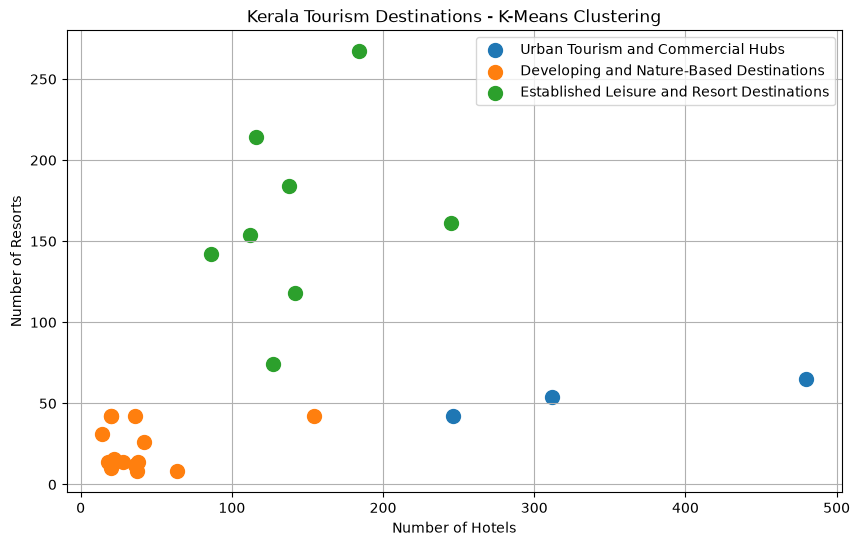

In [28]:
plt.figure(figsize=(10, 6))

for cluster in sorted(df_ml["Cluster"].unique()):

    cluster_data = df_ml[df_ml["Cluster"] == cluster]

    plt.scatter(
        cluster_data["Hotels"],
        cluster_data["Resorts"],
        label=cluster_names[cluster],
        s=100
    )

plt.xlabel("Number of Hotels")
plt.ylabel("Number of Resorts")
plt.title("Kerala Tourism Destinations - K-Means Clustering")

plt.legend()
plt.grid(True)
plt.show()

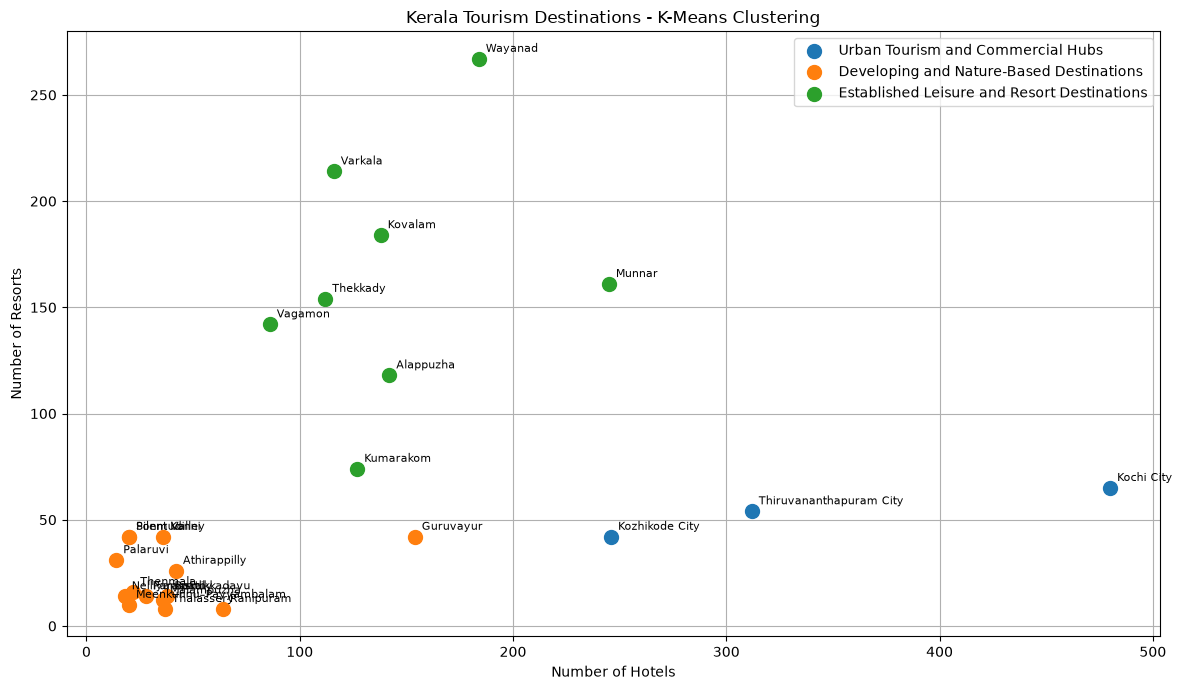

In [29]:
plt.figure(figsize=(12, 7))

for cluster in sorted(df_ml["Cluster"].unique()):

    cluster_data = df_ml[df_ml["Cluster"] == cluster]

    plt.scatter(
        cluster_data["Hotels"],
        cluster_data["Resorts"],
        label=cluster_names[cluster],
        s=100
    )

    for _, row in cluster_data.iterrows():

        plt.annotate(
            row["Destination"],
            (row["Hotels"], row["Resorts"]),
            fontsize=8,
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.xlabel("Number of Hotels")
plt.ylabel("Number of Resorts")

plt.title("Kerala Tourism Destinations - K-Means Clustering")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [30]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(df_scaled)

df_pca = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"]
)

df_pca["Destination"] = df_ml["Destination"].values
df_pca["Cluster"] = df_ml["Cluster"].values

print("PCA completed successfully!")

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_.round(4))

print(
    "\nTotal variance explained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

print("\nPCA dataset:")
print(df_pca.head())

PCA completed successfully!

Explained variance ratio:
[0.5248 0.2031]

Total variance explained: 72.79 %

PCA dataset:
        PC1       PC2 Destination  Cluster
0  2.534339  1.422282      Munnar        2
1  4.207486  2.783154     Wayanad        2
2  0.320056  1.517053     Vagamon        2
3  1.094736  2.054383    Thekkady        2
4  1.224278  0.417997   Alappuzha        2


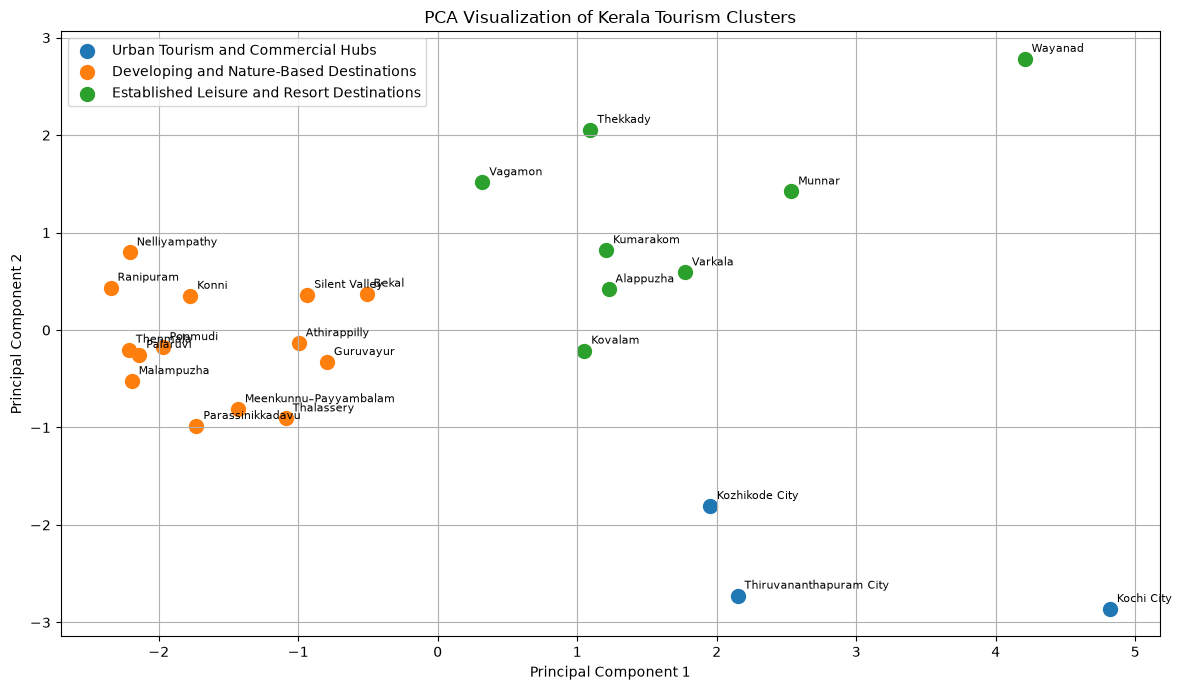

In [31]:
plt.figure(figsize=(12, 7))

for cluster in sorted(df_pca["Cluster"].unique()):

    cluster_data = df_pca[
        df_pca["Cluster"] == cluster
    ]

    plt.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        s=100,
        label=cluster_names[cluster]
    )

    for _, row in cluster_data.iterrows():

        plt.annotate(
            row["Destination"],
            (row["PC1"], row["PC2"]),
            fontsize=8,
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Visualization of Kerala Tourism Clusters")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [32]:
print("PC1 explained variance:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("PC2 explained variance:",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

print("Total explained variance:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

PC1 explained variance: 52.48 %
PC2 explained variance: 20.31 %
Total explained variance: 72.79 %


In [33]:
from sklearn.metrics import davies_bouldin_score

db_score = davies_bouldin_score(
    df_scaled,
    df_ml["Cluster"]
)

print("Davies-Bouldin Index:", round(db_score, 4))

Davies-Bouldin Index: 0.9875


In [34]:
from sklearn.metrics import calinski_harabasz_score

ch_score = calinski_harabasz_score(
    df_scaled,
    df_ml["Cluster"]
)

print("Calinski-Harabasz Score:", round(ch_score, 4))

Calinski-Harabasz Score: 15.3527


In [35]:
evaluation_results = pd.DataFrame({
    "Evaluation Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Score"
    ],
    "Result": [
        0.3899,
        0.9875,
        15.3527
    ]
})

print(evaluation_results)

evaluation_results.to_csv(
    "../08_Results/kmeans_evaluation_results.csv",
    index=False
)

print("\nEvaluation results saved successfully!")

         Evaluation Metric   Result
0         Silhouette Score   0.3899
1     Davies-Bouldin Index   0.9875
2  Calinski-Harabasz Score  15.3527

Evaluation results saved successfully!


In [36]:
business_analysis = df_ml[
    [
        "Destination",
        "District",
        "Cluster",
        "Cluster_Name",
        "Hotels",
        "Resorts",
        "Homestays_Vacation_Rentals",
        "Restaurants"
    ]
].copy()

cluster_averages = df_ml.groupby("Cluster")[
    [
        "Hotels",
        "Resorts",
        "Homestays_Vacation_Rentals",
        "Restaurants"
    ]
].transform("mean")

business_analysis["Hotel_Gap"] = (
    cluster_averages["Hotels"] - business_analysis["Hotels"]
)

business_analysis["Resort_Gap"] = (
    cluster_averages["Resorts"] - business_analysis["Resorts"]
)

business_analysis["Homestay_Gap"] = (
    cluster_averages["Homestays_Vacation_Rentals"]
    - business_analysis["Homestays_Vacation_Rentals"]
)

business_analysis["Restaurant_Gap"] = (
    cluster_averages["Restaurants"] - business_analysis["Restaurants"]
)

print(business_analysis.head(10).round(2).to_string(index=False))

   Destination           District  Cluster                                Cluster_Name  Hotels  Resorts  Homestays_Vacation_Rentals  Restaurants  Hotel_Gap  Resort_Gap  Homestay_Gap  Restaurant_Gap
        Munnar             Idukki        2 Established Leisure and Resort Destinations   245.0    161.0                       450.0        214.0    -101.25        3.25        -48.75          -21.75
       Wayanad            Wayanad        2 Established Leisure and Resort Destinations   184.0    267.0                       580.0        412.0     -40.25     -102.75       -178.75         -219.75
       Vagamon             Idukki        2 Established Leisure and Resort Destinations    86.0    142.0                       310.0         94.0      57.75       22.25         91.25           98.25
      Thekkady             Idukki        2 Established Leisure and Resort Destinations   112.0    154.0                       290.0        126.0      31.75       10.25        111.25           66.25
     Alapp

In [37]:
gap_columns = [
    "Hotel_Gap",
    "Resort_Gap",
    "Homestay_Gap",
    "Restaurant_Gap"
]

for column in gap_columns:

    print("\nTOP DESTINATIONS:", column)

    result = business_analysis.nlargest(
        5, column
    )

    print(
        result[
            ["Destination", "Cluster_Name", column]
        ].to_string(index=False)
    )


TOP DESTINATIONS: Hotel_Gap
            Destination                                Cluster_Name  Hotel_Gap
         Kozhikode City           Urban Tourism and Commercial Hubs     100.00
                Vagamon Established Leisure and Resort Destinations      57.75
Thiruvananthapuram City           Urban Tourism and Commercial Hubs      34.00
               Thekkady Established Leisure and Resort Destinations      31.75
                Varkala Established Leisure and Resort Destinations      27.75

TOP DESTINATIONS: Resort_Gap
Destination                                Cluster_Name  Resort_Gap
  Kumarakom Established Leisure and Resort Destinations   90.250000
  Alappuzha Established Leisure and Resort Destinations   46.250000
    Vagamon Established Leisure and Resort Destinations   22.250000
 Thalassery    Developing and Nature-Based Destinations   14.928571
  Ranipuram    Developing and Nature-Based Destinations   14.928571

TOP DESTINATIONS: Homestay_Gap
          Destination      

In [38]:
business_analysis["Overall_Gap_Score"] = (
    business_analysis[
        [
            "Hotel_Gap",
            "Resort_Gap",
            "Homestay_Gap",
            "Restaurant_Gap"
        ]
    ].mean(axis=1)
)

business_ranking = business_analysis[
    [
        "Destination",
        "District",
        "Cluster_Name",
        "Overall_Gap_Score"
    ]
].sort_values(
    by="Overall_Gap_Score",
    ascending=False
)

print("Top 10 Business Opportunity Candidates:")

print(
    business_ranking.head(10)
    .round(2)
    .to_string(index=False)
)

business_ranking.to_csv(
    "../08_Results/business_opportunity_ranking.csv",
    index=False
)

print("\nBusiness opportunity ranking saved successfully!")

Top 10 Business Opportunity Candidates:
            Destination           District                                Cluster_Name  Overall_Gap_Score
         Kozhikode City          Kozhikode           Urban Tourism and Commercial Hubs             130.08
              Kumarakom           Kottayam Established Leisure and Resort Destinations              94.12
                Vagamon             Idukki Established Leisure and Resort Destinations              67.38
               Thekkady             Idukki Established Leisure and Resort Destinations              54.88
Thiruvananthapuram City Thiruvananthapuram           Urban Tourism and Commercial Hubs              45.58
  Meenkunnu–Payyambalam             Kannur    Developing and Nature-Based Destinations              30.48
          Nelliyampathy           Palakkad    Developing and Nature-Based Destinations              28.73
              Ranipuram          Kasaragod    Developing and Nature-Based Destinations              21.23
      

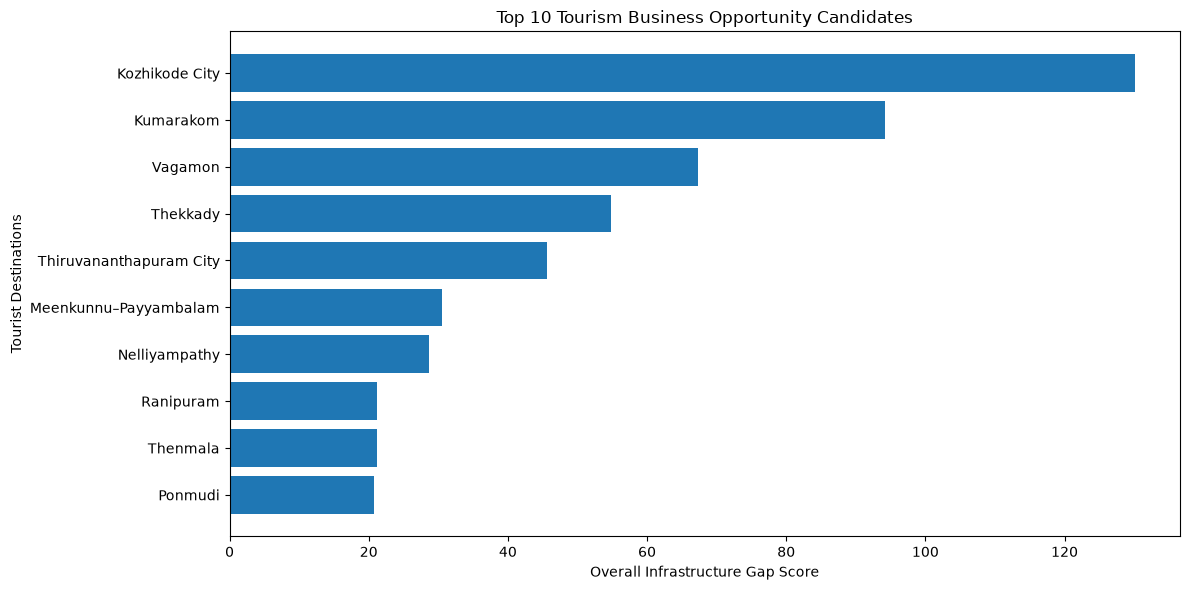

In [39]:
import matplotlib.pyplot as plt

top_10 = business_ranking.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_10["Destination"],
    top_10["Overall_Gap_Score"]
)

plt.xlabel("Overall Infrastructure Gap Score")
plt.ylabel("Tourist Destinations")
plt.title("Top 10 Tourism Business Opportunity Candidates")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [40]:
plt.savefig(
    "../09_Visualizations/top_10_business_opportunities.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [41]:
visitor_columns = [
    column for column in df.columns
    if "visitor" in column.lower()
    or "tourist" in column.lower()
]

print("Visitor-related columns:")
print(visitor_columns)

Visitor-related columns:
['Domestic_Visitors_2022', 'Foreign_Visitors_2022', 'Total_Visitors_2022', 'Visitor_Estimation_Note_2022', 'Visitor_Data_Type_2022', 'Visitor_Source_2022', 'Domestic_Visitors_2023', 'Foreign_Visitors_2023', 'Total_Visitors_2023', 'Visitor_Estimation_Note_2023', 'Visitor_Data_Type_2023', 'Visitor_Source_2023', 'Domestic_Visitors_2024', 'Foreign_Visitors_2024', 'Total_Visitors_2024', 'Visitor_Estimation_Note_2024', 'Visitor_Data_Type_2024', 'Visitor_Source_2024']


In [42]:
for year in [2022, 2023, 2024]:

    print(f"\nVisitor Data Quality - {year}")

    print(
        df[f"Visitor_Data_Type_{year}"]
        .value_counts(dropna=False)
    )

    print(
        "\nMissing total visitor values:",
        df[f"Total_Visitors_{year}"].isna().sum()
    )

    print(
        "Total visitors:",
        df[f"Total_Visitors_{year}"].sum()
    )


Visitor Data Quality - 2022
Visitor_Data_Type_2022
Calendar-year destination visits    25
Name: count, dtype: int64

Missing total visitor values: 0
Total visitors: 13115829

Visitor Data Quality - 2023
Visitor_Data_Type_2023
Calendar-year destination visits    25
Name: count, dtype: int64

Missing total visitor values: 0
Total visitors: 16131362

Visitor Data Quality - 2024
Visitor_Data_Type_2024
Calendar-year destination visits    25
Name: count, dtype: int64

Missing total visitor values: 0
Total visitors: 17573516


In [43]:
for year in [2022, 2023, 2024]:

    note_column = f"Visitor_Estimation_Note_{year}"

    estimated_data = df[
        df[note_column].notna()
        & (df[note_column].astype(str).str.strip() != "")
    ]

    print(f"\nEstimation Notes - {year}")
    print("Number of records with notes:", len(estimated_data))

    print(
        estimated_data[
            ["Destination", note_column]
        ].to_string(index=False)
    )


Estimation Notes - 2022
Number of records with notes: 13
     Destination                                                        Visitor_Estimation_Note_2022
         Vagamon † Provisional illustrative estimate from prior working table; not an official count
    Athirappilly † Provisional illustrative estimate from prior working table; not an official count
           Bekal † Provisional illustrative estimate from prior working table; not an official count
      Malampuzha † Provisional illustrative estimate from prior working table; not an official count
Parassinikkadavu † Provisional illustrative estimate from prior working table; not an official count
         Ponmudi † Provisional illustrative estimate from prior working table; not an official count
        Thenmala † Provisional illustrative estimate from prior working table; not an official count
           Konni † Provisional illustrative estimate from prior working table; not an official count
   Nelliyampathy † Provisional il

In [44]:
for year in [2022, 2023, 2024]:

    note_column = f"Visitor_Estimation_Note_{year}"
    total_column = f"Total_Visitors_{year}"

    estimated = (
        df[note_column].notna()
        & (df[note_column].astype(str).str.strip() != "")
    )

    estimated_total = df.loc[estimated, total_column].sum()
    non_estimated_total = df.loc[~estimated, total_column].sum()

    print(f"\nVisitor Summary - {year}")

    print("Estimated destinations:", estimated.sum())
    print("Estimated visitor total:", estimated_total)

    print("Destinations without estimation notes:", (~estimated).sum())
    print("Visitor total without estimation notes:", non_estimated_total)

    print("Combined visitor total:", estimated_total + non_estimated_total)


Visitor Summary - 2022
Estimated destinations: 13
Estimated visitor total: 2005968
Destinations without estimation notes: 12
Visitor total without estimation notes: 11109861
Combined visitor total: 13115829

Visitor Summary - 2023
Estimated destinations: 14
Estimated visitor total: 4250195
Destinations without estimation notes: 11
Visitor total without estimation notes: 11881167
Combined visitor total: 16131362

Visitor Summary - 2024
Estimated destinations: 14
Estimated visitor total: 2973037
Destinations without estimation notes: 11
Visitor total without estimation notes: 14600479
Combined visitor total: 17573516


In [45]:
visitor_analysis = df[["Destination"]].copy()

for year in [2022, 2023, 2024]:

    visitor_analysis[f"Visitors_{year}"] = df[
        f"Total_Visitors_{year}"
    ]

    notes = df[f"Visitor_Estimation_Note_{year}"]

    visitor_analysis[f"Status_{year}"] = notes.apply(
        lambda x: "Estimated"
        if pd.notna(x) and str(x).strip() != ""
        else "No estimation note"
    )

print(visitor_analysis.to_string(index=False))

visitor_analysis.to_csv(
    "../06_EDA_Analysis/destination_wise_visitor_analysis.csv",
    index=False
)

print("\nDestination-wise visitor analysis saved!")

            Destination  Visitors_2022        Status_2022  Visitors_2023        Status_2023  Visitors_2024        Status_2024
                 Munnar        1079320 No estimation note        1707059 No estimation note        2258056 No estimation note
                Wayanad         597947 No estimation note         677503 No estimation note         493458          Estimated
                Vagamon         238067          Estimated         303066 No estimation note         321841          Estimated
               Thekkady         581098 No estimation note         762197 No estimation note         738892 No estimation note
              Alappuzha         635496 No estimation note         570348 No estimation note         497872 No estimation note
              Kumarakom         292201 No estimation note         350609 No estimation note         484356 No estimation note
                Varkala         379634 No estimation note         491767 No estimation note         618562 No estimati

In [46]:
visitor_analysis["Growth_2022_2024"] = (
    (
        visitor_analysis["Visitors_2024"]
        - visitor_analysis["Visitors_2022"]
    )
    / visitor_analysis["Visitors_2022"]
) * 100

visitor_analysis["Data_Quality"] = visitor_analysis.apply(
    lambda row: "Contains estimates"
    if "Estimated" in [
        row["Status_2022"],
        row["Status_2023"],
        row["Status_2024"]
    ]
    else "No estimation notes",
    axis=1
)

visitor_growth = visitor_analysis.sort_values(
    by="Growth_2022_2024",
    ascending=False
)

print(
    visitor_growth[
        [
            "Destination",
            "Growth_2022_2024",
            "Data_Quality"
        ]
    ].round(2).to_string(index=False)
)

visitor_growth.to_csv(
    "../06_EDA_Analysis/visitor_growth_2022_2024.csv",
    index=False
)

print("\nVisitor growth analysis saved!")

            Destination  Growth_2022_2024        Data_Quality
                 Munnar            109.21 No estimation notes
              Kumarakom             65.76 No estimation notes
       Parassinikkadavu             65.30  Contains estimates
                Varkala             62.94 No estimation notes
              Guruvayur             61.29  Contains estimates
Thiruvananthapuram City             43.92 No estimation notes
             Malampuzha             42.02  Contains estimates
                Vagamon             35.19  Contains estimates
                Kovalam             31.63 No estimation notes
               Thekkady             27.15 No estimation notes
          Silent Valley             21.81  Contains estimates
             Kochi City             21.34 No estimation notes
              Ranipuram             20.74  Contains estimates
          Nelliyampathy             18.95  Contains estimates
               Thenmala             17.81  Contains estimates
        

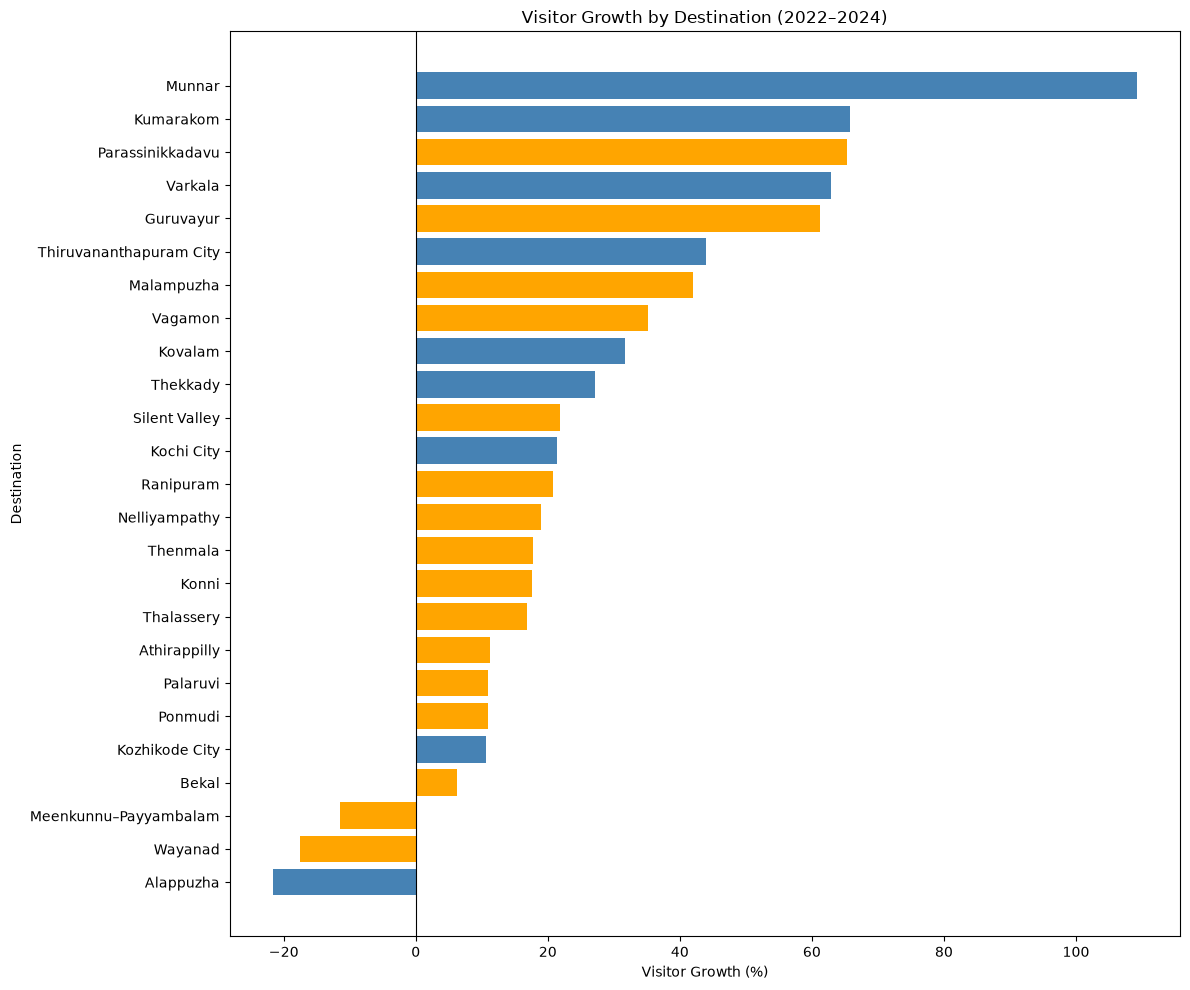

In [47]:
import matplotlib.pyplot as plt

plot_data = visitor_growth.sort_values(
    by="Growth_2022_2024",
    ascending=True
)

colors = [
    "orange" if status == "Contains estimates" else "steelblue"
    for status in plot_data["Data_Quality"]
]

plt.figure(figsize=(12, 10))

plt.barh(
    plot_data["Destination"],
    plot_data["Growth_2022_2024"],
    color=colors
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.xlabel("Visitor Growth (%)")
plt.ylabel("Destination")
plt.title("Visitor Growth by Destination (2022–2024)")

plt.tight_layout()

plt.savefig(
    "../09_Visualizations/visitor_growth_2022_2024.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [48]:
opportunity_analysis = business_ranking.merge(
    visitor_growth[
        [
            "Destination",
            "Growth_2022_2024",
            "Data_Quality"
        ]
    ],
    on="Destination",
    how="inner"
)

opportunity_analysis["Growth_Category"] = opportunity_analysis[
    "Growth_2022_2024"
].apply(
    lambda x: "Positive Growth" if x > 0 else "Negative Growth"
)

opportunity_analysis = opportunity_analysis.sort_values(
    by="Overall_Gap_Score",
    ascending=False
)

print(
    opportunity_analysis[
        [
            "Destination",
            "Overall_Gap_Score",
            "Growth_2022_2024",
            "Data_Quality",
            "Growth_Category"
        ]
    ].round(2).to_string(index=False)
)

            Destination  Overall_Gap_Score  Growth_2022_2024        Data_Quality Growth_Category
         Kozhikode City             130.08             10.70 No estimation notes Positive Growth
              Kumarakom              94.12             65.76 No estimation notes Positive Growth
                Vagamon              67.38             35.19  Contains estimates Positive Growth
               Thekkady              54.88             27.15 No estimation notes Positive Growth
Thiruvananthapuram City              45.58             43.92 No estimation notes Positive Growth
  Meenkunnu–Payyambalam              30.48            -11.53  Contains estimates Negative Growth
          Nelliyampathy              28.73             18.95  Contains estimates Positive Growth
              Ranipuram              21.23             20.74  Contains estimates Positive Growth
               Thenmala              21.23             17.81  Contains estimates Positive Growth
                Ponmudi       

In [49]:
def classify_opportunity(row):

    if row["Overall_Gap_Score"] > 0 and row["Growth_2022_2024"] > 0:
        return "High Gap + Positive Growth"

    elif row["Overall_Gap_Score"] > 0 and row["Growth_2022_2024"] <= 0:
        return "High Gap + Negative Growth"

    elif row["Overall_Gap_Score"] <= 0 and row["Growth_2022_2024"] > 0:
        return "Low Gap + Positive Growth"

    else:
        return "Low Gap + Negative Growth"


opportunity_analysis["Opportunity_Category"] = (
    opportunity_analysis.apply(
        classify_opportunity,
        axis=1
    )
)

print(
    opportunity_analysis[
        ["Destination", "Opportunity_Category"]
    ].to_string(index=False)
)

print("\nOpportunity Category Summary:")

print(
    opportunity_analysis["Opportunity_Category"]
    .value_counts()
)

            Destination       Opportunity_Category
         Kozhikode City High Gap + Positive Growth
              Kumarakom High Gap + Positive Growth
                Vagamon High Gap + Positive Growth
               Thekkady High Gap + Positive Growth
Thiruvananthapuram City High Gap + Positive Growth
  Meenkunnu–Payyambalam High Gap + Negative Growth
          Nelliyampathy High Gap + Positive Growth
              Ranipuram High Gap + Positive Growth
               Thenmala High Gap + Positive Growth
                Ponmudi High Gap + Positive Growth
                  Konni High Gap + Positive Growth
             Malampuzha High Gap + Positive Growth
                Kovalam High Gap + Positive Growth
                  Bekal High Gap + Positive Growth
       Parassinikkadavu High Gap + Positive Growth
           Athirappilly  Low Gap + Positive Growth
               Palaruvi  Low Gap + Positive Growth
                Varkala  Low Gap + Positive Growth
              Alappuzha  Low Ga

In [50]:
opportunity_analysis.to_csv(
    "../08_Results/final_business_opportunity_analysis.csv",
    index=False
)

category_summary = (
    opportunity_analysis["Opportunity_Category"]
    .value_counts()
    .reset_index()
)

category_summary.columns = [
    "Opportunity_Category",
    "Number_of_Destinations"
]

category_summary.to_csv(
    "../08_Results/opportunity_category_summary.csv",
    index=False
)

print("Final opportunity analysis saved successfully!")

print("\nCategory Summary:")
print(category_summary.to_string(index=False))


Final opportunity analysis saved successfully!

Category Summary:
      Opportunity_Category  Number_of_Destinations
High Gap + Positive Growth                      14
 Low Gap + Positive Growth                       8
 Low Gap + Negative Growth                       2
High Gap + Negative Growth                       1


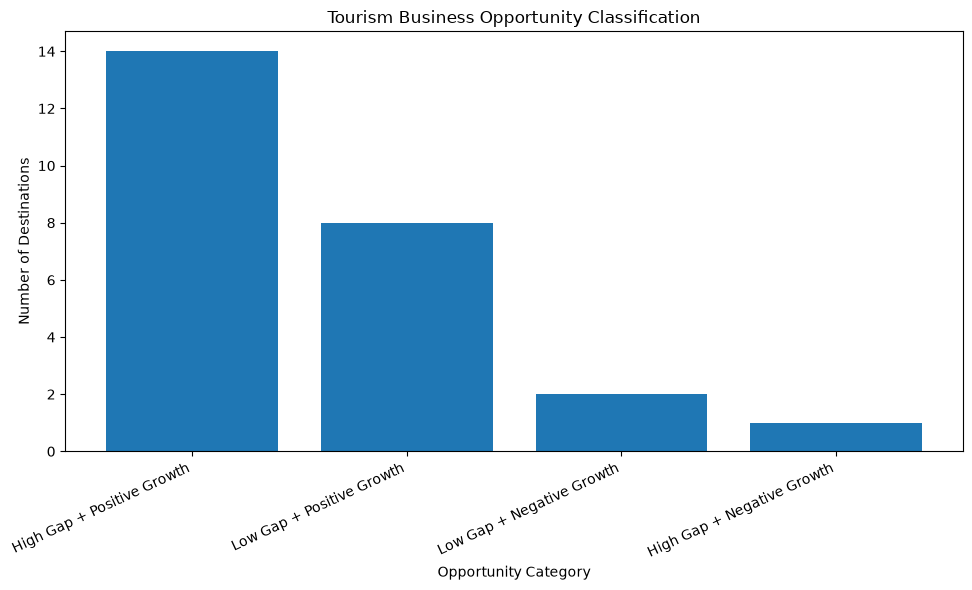

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    category_summary["Opportunity_Category"],
    category_summary["Number_of_Destinations"]
)

plt.xlabel("Opportunity Category")
plt.ylabel("Number of Destinations")
plt.title("Tourism Business Opportunity Classification")

plt.xticks(rotation=25, ha="right")

plt.tight_layout()

plt.savefig(
    "../09_Visualizations/opportunity_category_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [52]:
top_destinations = [
    "Kozhikode City",
    "Kumarakom",
    "Vagamon",
    "Thekkady"
]

recommendation_data = opportunity_analysis[
    opportunity_analysis["Destination"].isin(top_destinations)
].copy()

gap_mapping = {
    "Hotel_Gap": "Hotels",
    "Resort_Gap": "Resorts",
    "Homestay_Gap": "Homestays",
    "Restaurant_Gap": "Restaurants"
}

recommendations = []

for _, row in recommendation_data.iterrows():

    business_areas = []

    for column, business_name in gap_mapping.items():

        if row[column] > 0:
            business_areas.append(business_name)

    recommendations.append({
        "Destination": row["Destination"],
        "Cluster": row["Cluster_Name"],
        "Visitor_Growth_Percent": row["Growth_2022_2024"],
        "Potential_Business_Areas": ", ".join(business_areas)
    })

recommendation_table = pd.DataFrame(recommendations)

print(recommendation_table.to_string(index=False))

recommendation_table.to_csv(
    "../08_Results/destination_business_recommendations.csv",
    index=False
)

print("\nBusiness recommendations saved successfully!")

KeyError: 'Hotel_Gap'

In [53]:
top_destinations = [
    "Kozhikode City",
    "Kumarakom",
    "Vagamon",
    "Thekkady"
]

recommendation_data = opportunity_analysis.merge(
    business_analysis[
        [
            "Destination",
            "Hotel_Gap",
            "Resort_Gap",
            "Homestay_Gap",
            "Restaurant_Gap"
        ]
    ],
    on="Destination",
    how="left"
)

recommendation_data = recommendation_data[
    recommendation_data["Destination"].isin(top_destinations)
].copy()

gap_mapping = {
    "Hotel_Gap": "Hotels",
    "Resort_Gap": "Resorts",
    "Homestay_Gap": "Homestays",
    "Restaurant_Gap": "Restaurants"
}

recommendations = []

for _, row in recommendation_data.iterrows():

    business_areas = []

    for column, business_name in gap_mapping.items():

        if row[column] > 0:
            business_areas.append(business_name)

    recommendations.append({
        "Destination": row["Destination"],
        "Cluster": row["Cluster_Name"],
        "Visitor_Growth_Percent": row["Growth_2022_2024"],
        "Potential_Business_Areas": ", ".join(business_areas)
    })

recommendation_table = pd.DataFrame(recommendations)

print(recommendation_table.to_string(index=False))

   Destination                                     Cluster  Visitor_Growth_Percent                Potential_Business_Areas
Kozhikode City           Urban Tourism and Commercial Hubs               10.702912 Hotels, Resorts, Homestays, Restaurants
     Kumarakom Established Leisure and Resort Destinations               65.761240 Hotels, Resorts, Homestays, Restaurants
       Vagamon Established Leisure and Resort Destinations               35.189253 Hotels, Resorts, Homestays, Restaurants
      Thekkady Established Leisure and Resort Destinations               27.154456 Hotels, Resorts, Homestays, Restaurants


In [54]:
recommendation_table.to_csv(
    "../08_Results/destination_business_recommendations.csv",
    index=False
)

print("Destination business recommendations saved successfully!")

Destination business recommendations saved successfully!


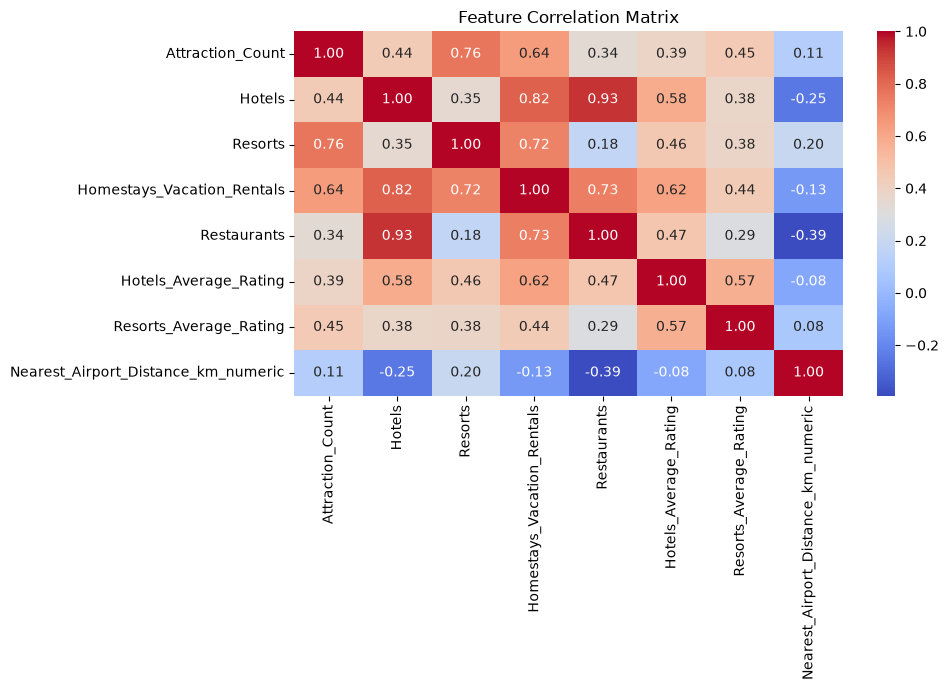

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = df_scaled.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

In [56]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

new_features = [
    "Attraction_Count",
    "Hotels",
    "Resorts",
    "Homestays_Vacation_Rentals",
    "Hotels_Average_Rating",
    "Resorts_Average_Rating",
    "Nearest_Airport_Distance_km_numeric"
]

scaler_new = StandardScaler()

scaled_new = scaler_new.fit_transform(
    df_ml[new_features]
)

kmeans_new = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

new_labels = kmeans_new.fit_predict(scaled_new)

new_score = silhouette_score(
    scaled_new,
    new_labels
)

print("Original Silhouette Score: 0.3899")
print("New Silhouette Score:", round(new_score, 4))

Original Silhouette Score: 0.3899
New Silhouette Score: 0.3578


In [57]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_results = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(df_scaled)

    score = silhouette_score(df_scaled, labels)

    silhouette_results.append((k, score))

for k, score in silhouette_results:
    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3559
K = 3, Silhouette Score = 0.3899
K = 4, Silhouette Score = 0.3501
K = 5, Silhouette Score = 0.2501
K = 6, Silhouette Score = 0.2424
K = 7, Silhouette Score = 0.2303
K = 8, Silhouette Score = 0.1790


In [58]:
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

robust_scaler = RobustScaler()

robust_data = robust_scaler.fit_transform(
    df_ml[features]
)

robust_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

robust_labels = robust_kmeans.fit_predict(robust_data)

robust_score = silhouette_score(
    robust_data,
    robust_labels
)

print("Original Score:", 0.3899)
print("RobustScaler Score:", round(robust_score, 4))

Original Score: 0.3899
RobustScaler Score: 0.5804


In [59]:
df_ml["Robust_Cluster"] = robust_labels

print("Cluster Sizes:")

print(
    df_ml["Robust_Cluster"].value_counts().sort_index()
)

print("\nDestinations in Each Cluster:")

for cluster in sorted(df_ml["Robust_Cluster"].unique()):

    print(f"\nCluster {cluster}:")

    print(
        df_ml.loc[
            df_ml["Robust_Cluster"] == cluster,
            "Destination"
        ].tolist()
    )

Cluster Sizes:
Robust_Cluster
0     3
1    20
2     2
Name: count, dtype: int64

Destinations in Each Cluster:

Cluster 0:
['Kochi City', 'Kozhikode City', 'Thiruvananthapuram City']

Cluster 1:
['Vagamon', 'Thekkady', 'Alappuzha', 'Kumarakom', 'Varkala', 'Kovalam', 'Guruvayur', 'Athirappilly', 'Bekal', 'Malampuzha', 'Parassinikkadavu', 'Ponmudi', 'Thenmala', 'Konni', 'Nelliyampathy', 'Silent Valley', 'Thalassery', 'Ranipuram', 'Palaruvi', 'Meenkunnu–Payyambalam']

Cluster 2:
['Munnar', 'Wayanad']


In [60]:
from sklearn.metrics import silhouette_samples
import pandas as pd

sample_scores = silhouette_samples(
    robust_data,
    robust_labels
)

silhouette_analysis = pd.DataFrame({
    "Cluster": robust_labels,
    "Silhouette_Score": sample_scores
})

print("Average Silhouette Score by Cluster:")

print(
    silhouette_analysis.groupby("Cluster")[
        "Silhouette_Score"
    ].mean().round(4)
)

Average Silhouette Score by Cluster:
Cluster
0    0.4943
1    0.6332
2    0.1814
Name: Silhouette_Score, dtype: float64


In [61]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for n in [10, 20, 30, 50, 100]:

    model = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=n
    )

    labels = model.fit_predict(robust_data)

    score = silhouette_score(
        robust_data,
        labels
    )

    print(f"n_init = {n}, Silhouette Score = {score:.4f}")

n_init = 10, Silhouette Score = 0.5804
n_init = 20, Silhouette Score = 0.5804
n_init = 30, Silhouette Score = 0.5804
n_init = 50, Silhouette Score = 0.5804
n_init = 100, Silhouette Score = 0.5804


In [62]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for components in [2, 3, 4, 5]:

    pca = PCA(n_components=components)

    pca_data = pca.fit_transform(robust_data)

    model = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(pca_data)

    score = silhouette_score(pca_data, labels)

    variance = sum(pca.explained_variance_ratio_) * 100

    print(
        f"Components: {components}, "
        f"Silhouette: {score:.4f}, "
        f"Variance: {variance:.2f}%"
    )

Components: 2, Silhouette: 0.6799, Variance: 88.71%
Components: 3, Silhouette: 0.6353, Variance: 93.30%
Components: 4, Silhouette: 0.6115, Variance: 95.82%
Components: 5, Silhouette: 0.5922, Variance: 97.99%


In [63]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

pca_final = PCA(n_components=2)

pca_2_data = pca_final.fit_transform(robust_data)

kmeans_pca = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

pca_labels = kmeans_pca.fit_predict(pca_2_data)

print("Cluster Sizes:")

print(
    pd.Series(pca_labels)
    .value_counts()
    .sort_index()
)

print("\nDestinations in Each Cluster:")

for cluster in sorted(set(pca_labels)):

    print(f"\nCluster {cluster}:")

    print(
        df_ml.loc[
            pca_labels == cluster,
            "Destination"
        ].tolist()
    )

Cluster Sizes:
0     3
1    20
2     2
Name: count, dtype: int64

Destinations in Each Cluster:

Cluster 0:
['Kochi City', 'Kozhikode City', 'Thiruvananthapuram City']

Cluster 1:
['Vagamon', 'Thekkady', 'Alappuzha', 'Kumarakom', 'Varkala', 'Kovalam', 'Guruvayur', 'Athirappilly', 'Bekal', 'Malampuzha', 'Parassinikkadavu', 'Ponmudi', 'Thenmala', 'Konni', 'Nelliyampathy', 'Silent Valley', 'Thalassery', 'Ranipuram', 'Palaruvi', 'Meenkunnu–Payyambalam']

Cluster 2:
['Munnar', 'Wayanad']


In [64]:
from sklearn.metrics import silhouette_score

pca_score = silhouette_score(
    pca_2_data,
    pca_labels
)

original_space_score = silhouette_score(
    robust_data,
    pca_labels
)

print("Silhouette Score in PCA space:", round(pca_score, 4))

print(
    "Silhouette Score in original feature space:",
    round(original_space_score, 4)
)

Silhouette Score in PCA space: 0.6799
Silhouette Score in original feature space: 0.5804


In [65]:
comparison = pd.DataFrame({
    "Destination": df_ml["Destination"],
    "Original_Cluster": df_ml["Cluster"],
    "New_Cluster": pca_labels
})

comparison["Same_Cluster"] = (
    comparison["Original_Cluster"]
    == comparison["New_Cluster"]
)

print(comparison.to_string(index=False))

print(
    "\nDestinations with changed assignments:",
    (~comparison["Same_Cluster"]).sum()
)

            Destination  Original_Cluster  New_Cluster  Same_Cluster
                 Munnar                 2            2          True
                Wayanad                 2            2          True
                Vagamon                 2            1         False
               Thekkady                 2            1         False
              Alappuzha                 2            1         False
              Kumarakom                 2            1         False
                Varkala                 2            1         False
                Kovalam                 2            1         False
             Kochi City                 0            0          True
         Kozhikode City                 0            0          True
Thiruvananthapuram City                 0            0          True
              Guruvayur                 1            1          True
           Athirappilly                 1            1          True
                  Bekal           

In [66]:
from sklearn.metrics import davies_bouldin_score

original_db = davies_bouldin_score(
    df_scaled,
    df_ml["Cluster"]
)

robust_db = davies_bouldin_score(
    robust_data,
    robust_labels
)

print("Original Model DB Index:", round(original_db, 4))
print("RobustScaler Model DB Index:", round(robust_db, 4))

Original Model DB Index: 0.9875
RobustScaler Model DB Index: 0.6431


In [67]:
from sklearn.metrics import calinski_harabasz_score

original_ch = calinski_harabasz_score(
    df_scaled,
    df_ml["Cluster"]
)

robust_ch = calinski_harabasz_score(
    robust_data,
    robust_labels
)

print("Original Model CH Score:", round(original_ch, 4))
print("RobustScaler Model CH Score:", round(robust_ch, 4))

Original Model CH Score: 15.3527
RobustScaler Model CH Score: 28.2081


In [68]:
model_comparison = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index"
    ],
    "StandardScaler": [
        0.3899,
        0.9875,
        15.3527
    ],
    "RobustScaler": [
        0.5804,
        0.6431,
        28.2081
    ]
})

print(model_comparison.to_string(index=False))

model_comparison.to_csv(
    "../08_Results/model_comparison.csv",
    index=False
)

print("\nModel comparison saved successfully!")

                 Metric  StandardScaler  RobustScaler
       Silhouette Score          0.3899        0.5804
   Davies-Bouldin Index          0.9875        0.6431
Calinski-Harabasz Index         15.3527       28.2081

Model comparison saved successfully!


In [69]:
df_ml["Robust_Cluster"] = robust_labels

robust_profiles = df_ml.groupby(
    "Robust_Cluster"
)[features].mean()

print(
    robust_profiles.round(2).to_string()
)

                Attraction_Count  Hotels  Resorts  Homestays_Vacation_Rentals  Restaurants  Hotels_Average_Rating  Resorts_Average_Rating  Nearest_Airport_Distance_km_numeric
Robust_Cluster                                                                                                                                                                
0                           4.67   346.0    53.67                       490.0       912.67                   4.17                    4.40                                22.33
1                           2.95    63.5    60.35                       170.6        83.25                   4.01                    4.32                                73.75
2                          13.00   214.5   214.00                       515.0       313.00                   4.15                    4.45                               103.50


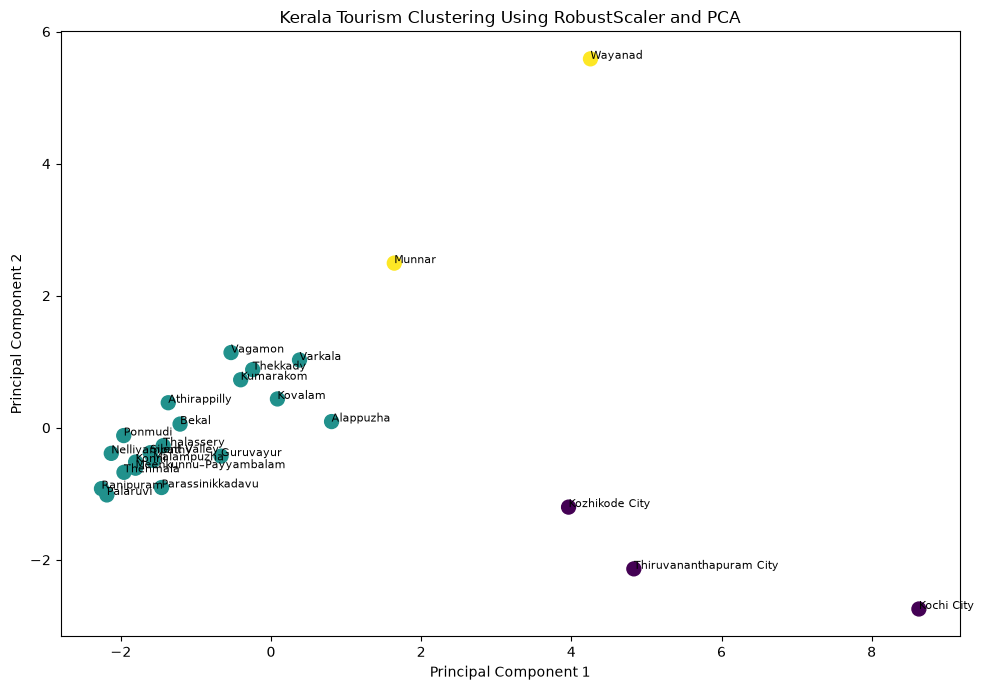

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    pca_2_data[:, 0],
    pca_2_data[:, 1],
    c=robust_labels,
    cmap="viridis",
    s=100
)

for i, destination in enumerate(df_ml["Destination"]):
    plt.annotate(
        destination,
        (pca_2_data[i, 0], pca_2_data[i, 1]),
        fontsize=8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    "Kerala Tourism Clustering Using RobustScaler and PCA"
)

plt.tight_layout()

plt.savefig(
    "../09_Visualizations/robust_pca_clustering.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

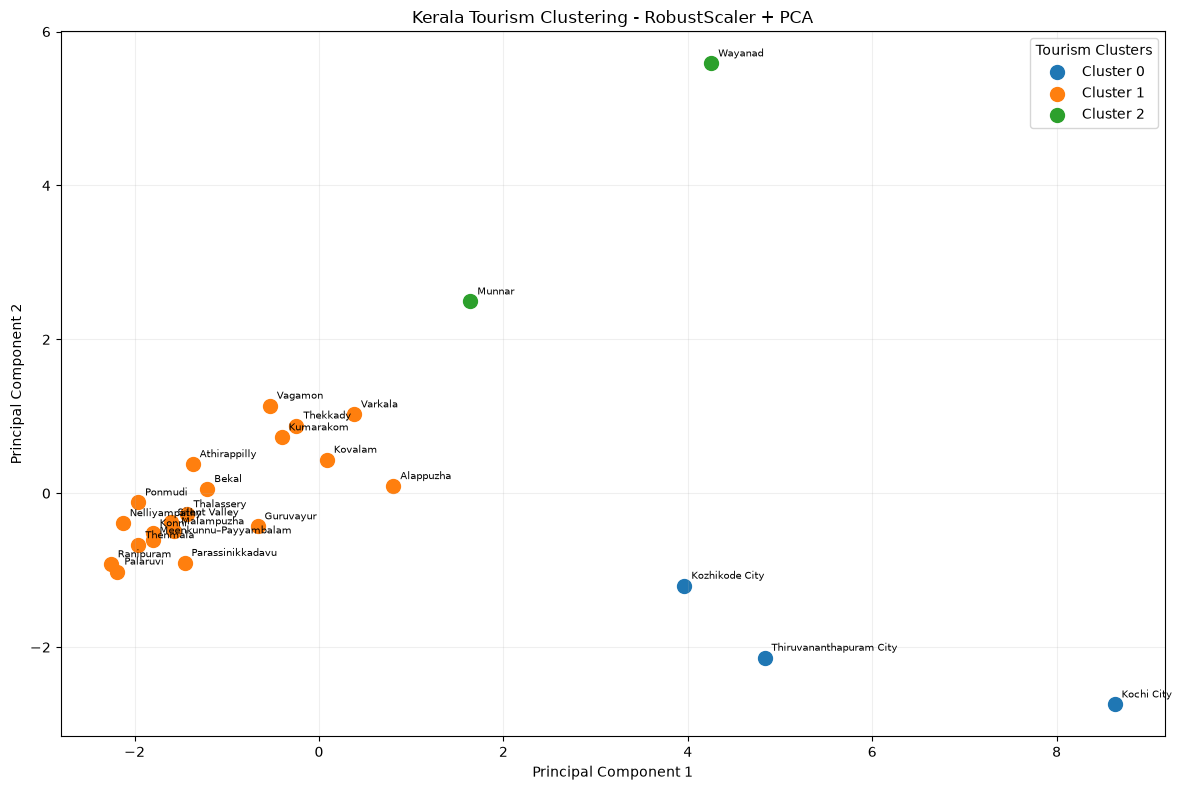

In [71]:
plt.figure(figsize=(12, 8))

for cluster in sorted(set(robust_labels)):

    mask = robust_labels == cluster

    plt.scatter(
        pca_2_data[mask, 0],
        pca_2_data[mask, 1],
        s=100,
        label=f"Cluster {cluster}"
    )

for i, destination in enumerate(df_ml["Destination"]):

    plt.annotate(
        destination,
        (pca_2_data[i, 0], pca_2_data[i, 1]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("Kerala Tourism Clustering - RobustScaler + PCA")

plt.legend(title="Tourism Clusters")

plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "../09_Visualizations/robust_pca_clustering_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [72]:
robust_results = df_ml[
    ["Destination", "District"]
].copy()

robust_results["Cluster"] = robust_labels

robust_cluster_names = {
    0: "Urban Tourism and Commercial Hubs",
    1: "Mixed Tourism Destinations",
    2: "High-Infrastructure Nature Destinations"
}

robust_results["Cluster_Name"] = (
    robust_results["Cluster"].map(robust_cluster_names)
)

robust_results.to_csv(
    "../07_Machine_Learning/robust_scaler_cluster_assignments.csv",
    index=False
)

print("RobustScaler cluster assignments saved!")
print(robust_results.to_string(index=False))

RobustScaler cluster assignments saved!
            Destination           District  Cluster                            Cluster_Name
                 Munnar             Idukki        2 High-Infrastructure Nature Destinations
                Wayanad            Wayanad        2 High-Infrastructure Nature Destinations
                Vagamon             Idukki        1              Mixed Tourism Destinations
               Thekkady             Idukki        1              Mixed Tourism Destinations
              Alappuzha          Alappuzha        1              Mixed Tourism Destinations
              Kumarakom           Kottayam        1              Mixed Tourism Destinations
                Varkala Thiruvananthapuram        1              Mixed Tourism Destinations
                Kovalam Thiruvananthapuram        1              Mixed Tourism Destinations
             Kochi City          Ernakulam        0       Urban Tourism and Commercial Hubs
         Kozhikode City          Kozhiko

In [73]:
robust_profiles.to_csv(
    "../08_Results/robust_cluster_profiles.csv"
)

print("RobustScaler cluster profiles saved successfully!")

RobustScaler cluster profiles saved successfully!


In [74]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

pca_evaluation = {
    "Silhouette Score": silhouette_score(
        pca_2_data, pca_labels
    ),
    "Davies-Bouldin Index": davies_bouldin_score(
        pca_2_data, pca_labels
    ),
    "Calinski-Harabasz Index": calinski_harabasz_score(
        pca_2_data, pca_labels
    )
}

print("RobustScaler + PCA Evaluation")

for metric, score in pca_evaluation.items():
    print(f"{metric}: {score:.4f}")

RobustScaler + PCA Evaluation
Silhouette Score: 0.6799
Davies-Bouldin Index: 0.5692
Calinski-Harabasz Index: 45.8110


In [75]:
pca_evaluation_df = pd.DataFrame({
    "Evaluation_Metric": list(pca_evaluation.keys()),
    "Result": list(pca_evaluation.values())
})

print(pca_evaluation_df.round(4).to_string(index=False))

pca_evaluation_df.to_csv(
    "../08_Results/robust_pca_evaluation.csv",
    index=False
)

print("\nPCA evaluation results saved successfully!")

      Evaluation_Metric  Result
       Silhouette Score  0.6799
   Davies-Bouldin Index  0.5692
Calinski-Harabasz Index 45.8110

PCA evaluation results saved successfully!


In [76]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "StandardScaler + K-Means",
        "RobustScaler + K-Means",
        "RobustScaler + PCA + K-Means"
    ],

    "Silhouette_Score": [
        0.3899,
        0.5804,
        0.6799
    ],

    "Davies_Bouldin_Index": [
        0.9875,
        0.6431,
        0.5692
    ],

    "Calinski_Harabasz_Index": [
        15.3527,
        28.2081,
        45.8110
    ],

    "Evaluation_Space": [
        "Original 8 features",
        "Original 8 features",
        "2 PCA components"
    ]
})

print(final_model_comparison.to_string(index=False))

final_model_comparison.to_csv(
    "../08_Results/final_model_comparison.csv",
    index=False
)

print("\nFinal model comparison saved successfully!")

                       Model  Silhouette_Score  Davies_Bouldin_Index  Calinski_Harabasz_Index    Evaluation_Space
    StandardScaler + K-Means            0.3899                0.9875                  15.3527 Original 8 features
      RobustScaler + K-Means            0.5804                0.6431                  28.2081 Original 8 features
RobustScaler + PCA + K-Means            0.6799                0.5692                  45.8110    2 PCA components

Final model comparison saved successfully!


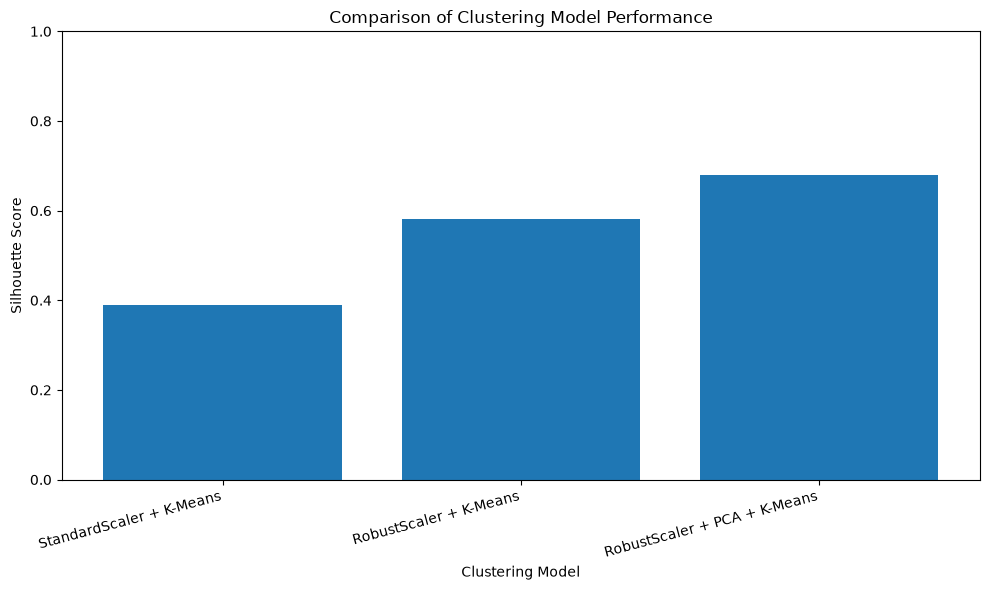

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    final_model_comparison["Model"],
    final_model_comparison["Silhouette_Score"]
)

plt.ylabel("Silhouette Score")
plt.xlabel("Clustering Model")
plt.title("Comparison of Clustering Model Performance")

plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")

plt.tight_layout()

plt.savefig(
    "../09_Visualizations/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Cluster Distribution Comparison:
   StandardScaler  RobustScaler
0               3             3
1              14            20
2               8             2


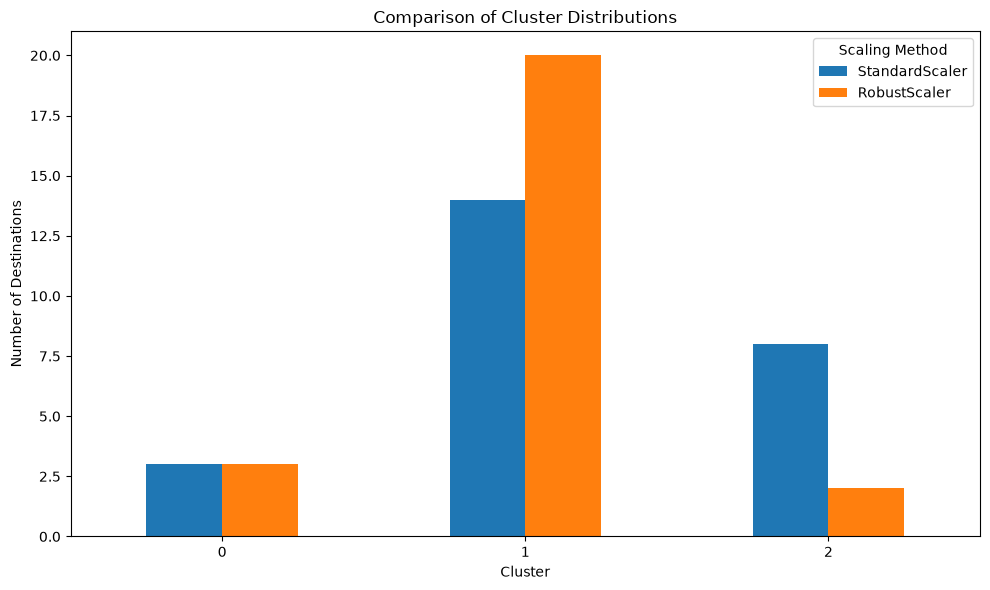

In [78]:
import pandas as pd
import matplotlib.pyplot as plt

original_counts = df_ml["Cluster"].value_counts().sort_index()

robust_counts = pd.Series(
    robust_labels
).value_counts().sort_index()

comparison_counts = pd.DataFrame({
    "StandardScaler": original_counts,
    "RobustScaler": robust_counts
})

print("Cluster Distribution Comparison:")
print(comparison_counts)

comparison_counts.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Cluster")
plt.ylabel("Number of Destinations")
plt.title("Comparison of Cluster Distributions")

plt.xticks(rotation=0)
plt.legend(title="Scaling Method")
plt.tight_layout()

plt.savefig(
    "../09_Visualizations/cluster_distribution_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [79]:
final_model_decision = pd.DataFrame({
    "Model": [
        "StandardScaler + K-Means",
        "RobustScaler + K-Means",
        "RobustScaler + PCA + K-Means"
    ],
    "Purpose": [
        "Main tourism segmentation model",
        "Alternative clustering experiment",
        "Dimensionality reduction and visualization"
    ],
    "Decision": [
        "Selected for business analysis",
        "Retained for comparison",
        "Retained for comparison"
    ]
})

print(final_model_decision.to_string(index=False))

final_model_decision.to_csv(
    "../08_Results/final_model_selection.csv",
    index=False
)

print("\nFinal model selection saved successfully!")

                       Model                                    Purpose                       Decision
    StandardScaler + K-Means            Main tourism segmentation model Selected for business analysis
      RobustScaler + K-Means          Alternative clustering experiment        Retained for comparison
RobustScaler + PCA + K-Means Dimensionality reduction and visualization        Retained for comparison

Final model selection saved successfully!


In [80]:
print("Original Cluster Distribution:")
print(df_ml["Cluster"].value_counts().sort_index())

print("\nBusiness Analysis Cluster Distribution:")
print(business_analysis["Cluster"].value_counts().sort_index())

print("\nChecking cluster consistency:")

print(
    df_ml["Cluster"].equals(
        business_analysis["Cluster"]
    )
)

Original Cluster Distribution:
Cluster
0     3
1    14
2     8
Name: count, dtype: int64

Business Analysis Cluster Distribution:
Cluster
0     3
1    14
2     8
Name: count, dtype: int64

Checking cluster consistency:
True


In [82]:
import os

folders = [
    "../07_Machine_Learning",
    "../08_Results",
    "../09_Visualizations"
]

for folder in folders:

    print(f"\n{folder}")

    for file in sorted(os.listdir(folder)):
        if os.path.isfile(os.path.join(folder, file)):
            print(" -", file)


../07_Machine_Learning
 - kerala_tourism_cluster_assignments.csv
 - robust_scaler_cluster_assignments.csv

../08_Results
 - business_opportunity_ranking.csv
 - destination_business_recommendations.csv
 - final_business_opportunity_analysis.csv
 - final_model_comparison.csv
 - final_model_selection.csv
 - kmeans_evaluation_results.csv
 - model_comparison.csv
 - opportunity_category_summary.csv
 - robust_cluster_profiles.csv
 - robust_pca_evaluation.csv

../09_Visualizations
 - cluster_distribution_comparison.png
 - final_model_comparison.png
 - opportunity_category_summary.png
 - robust_pca_clustering.png
 - robust_pca_clustering_final.png
 - top_10_business_opportunities.png
 - visitor_growth_2022_2024.png


In [83]:
original_profiles = df_ml.groupby("Cluster")[features].mean()

original_profiles.to_csv(
    "../08_Results/original_cluster_profiles.csv"
)

print("Original cluster profiles:")
print(original_profiles.round(2))

print("\nOriginal cluster profiles saved successfully!")

Original cluster profiles:
         Attraction_Count  Hotels  Resorts  Homestays_Vacation_Rentals  \
Cluster                                                                  
0                    4.67  346.00    53.67                      490.00   
1                    2.36   39.21    22.93                       88.00   
2                    6.50  143.75   164.25                      401.25   

         Restaurants  Hotels_Average_Rating  Resorts_Average_Rating  \
Cluster                                                               
0             912.67                   4.17                    4.40   
1              53.79                   3.96                    4.27   
2             192.25                   4.14                    4.44   

         Nearest_Airport_Distance_km_numeric  
Cluster                                       
0                                      22.33  
1                                      70.71  
2                                      86.50  

Original c